# Feature importances with a forest of trees: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/ensemble/plot_forest_importances.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/ensemble/plot_forest_importances.html)).

**Scenario:** `RandomForestClassifier(random_state=0)` (100 trees, default parameters) on a 10-feature
`make_classification` task with 3 informative features. The mean decrease in impurity
(`feature_importances_`) is plotted with its inter-tree standard deviation (computed from
`estimators_[i].feature_importances_`). The example then computes permutation importances on the held-out set.

**Adaptations**
- Data and parameters are unchanged; `make_classification` and the stratified `train_test_split` run in Python
  and the arrays are shared with Mojo. Labels are shared as Float64 (Moxie forests take Float64 class labels).
- Moxie forests take Float32 feature matrices; scikit-learn casts `X` to float32 internally, so both sides train
  on identical values.
- `estimators_` is the method `estimators_()` in Moxie (a borrow of the fitted member list).
- pandas `Series.plot.bar` becomes matplotlib `bar`, since Moxie produces arrays, not pandas output.
- **GAP:** `sklearn.inspection.permutation_importance` has no Moxie counterpart (there is no
  `moxie.inspection`); that half of the example runs only in Python.
- Timing prints are kept for the reference but are not compared.

**Determinism:** deterministic (integer `random_state` for the split and the forest), so importances, member
importances and predictions must match.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("ensemble/plot_forest_importances")

## 1. scikit-learn (Python reference)

The official example code, MDI part; plotting is deferred to the side-by-side figure.

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=3,
    n_redundant=0,
    n_repeated=0,
    n_classes=2,
    random_state=0,
    shuffle=False,
)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

feature_names = [f"feature {i}" for i in range(X.shape[1])]
forest = RandomForestClassifier(random_state=0)
forest.fit(X_train, y_train)

start_time = time.time()
importances = forest.feature_importances_
std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

sk_members = np.stack([tree.feature_importances_ for tree in forest.estimators_])
sk_proba = forest.predict_proba(X_test)
sk_pred = forest.predict(X_test)
sk_score = forest.score(X_test, y_test)
sk_apply = forest.apply(X_test)
print("sklearn test accuracy:", sk_score)
nb.share(X_train=X_train, y_train=y_train.astype(np.float64), X_test=X_test, y_test=y_test.astype(np.float64))

Elapsed time to compute the importances: 0.005 seconds
sklearn test accuracy: 0.892


Permutation importance (reference only; see the GAP note).

In [3]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    forest, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")
perm_mean, perm_std = result.importances_mean, result.importances_std

Elapsed time to compute the importances: 1.066 seconds


## 2. Moxie (native Mojo)

The forest is fitted and inspected in Mojo; per-tree importances come from `estimators_()`.

In [4]:
%%mojo forest_importances
from moxie.ensemble import RandomForestClassifier
from moxie_nb_io import load, save, save_floats
import numojo as nm


def main() raises:
    var X_train = load[DType.float32]("X_train")
    var y_train = load("y_train")
    var X_test = load[DType.float32]("X_test")
    var y_test = load("y_test")
    var forest = RandomForestClassifier(random_state=0)
    _ = forest.fit(X_train, y_train)
    save("importances", forest.feature_importances_)
    # Per-tree importances, the input of the example's inter-tree standard deviation.
    var p = forest.n_features_in_
    var members = nm.zeros[DType.float64](nm.Shape(len(forest), p))
    for m in range(len(forest)):
        for j in range(p):
            members.unsafe_set(m * p + j, forest.estimators_()[m].feature_importances_.unsafe_get(j))
    save("members", members)
    save("proba", forest.predict_proba(X_test))
    save("pred", forest.predict(X_test))
    save("apply", forest.apply(X_test))
    var score = List[Float64]()
    score.append(forest.score(X_test, y_test))
    save_floats("score", score)
    print("moxie test accuracy:", score[0], "trees:", len(forest))

moxie test accuracy: 0.892 trees: 100


## 3. Side by side and parity

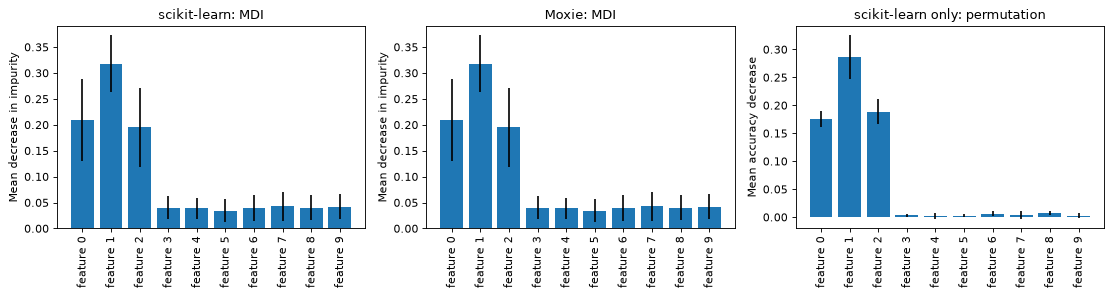

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
predict(X_test),PASS,"(250,)","(250,)",,,exact,0 mismatches,
predict_proba(X_test),PASS,"(250, 2)","(250, 2)",,,exact,0 mismatches,
apply(X_test),PASS,"(250, 100)","(250, 100)",,,exact,0 mismatches,
"score(X_test, y_test)",PASS,(),(),,,exact,0 mismatches,
feature_importances_,PASS,"(10,)","(10,)",2.78e-17,1.8e-16,"rtol=1e-12, atol=1e-15",,"identical trees; impurity decreases are accumulated and normalized in a different order than scikit-learn's Cython, which leaves last-ulp differences"
estimators_[i].feature_importances_ (100 x 10),PASS,"(100, 10)","(100, 10)",1.11e-16,3.87e-16,"rtol=1e-12, atol=1e-15",,same per-tree accumulation-order argument as the forest mean
inter-tree std of importances,PASS,"(10,)","(10,)",6.94e-18,1.27e-16,"rtol=1e-10, atol=1e-15",,NumPy std of member importances that agree to 1e-12
permutation_importance,GAP,,,,,,sklearn.inspection.permutation_importance has no Moxie counterpart (no moxie.inspection module); the permutation half of the example is reference-only,


In [5]:
mx = nb.results["forest_importances"]
mx_std = np.std(mx["members"], axis=0)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), dpi=80)
for ax, imp, err, title in ((axes[0], importances, std, "scikit-learn: MDI"),
                            (axes[1], mx["importances"], mx_std, "Moxie: MDI")):
    ax.bar(feature_names, imp, yerr=err)
    ax.set_title(title); ax.set_ylabel("Mean decrease in impurity")
    ax.tick_params(axis="x", rotation=90)
axes[2].bar(feature_names, perm_mean, yerr=perm_std)
axes[2].set_title("scikit-learn only: permutation"); axes[2].set_ylabel("Mean accuracy decrease")
axes[2].tick_params(axis="x", rotation=90)
fig.tight_layout()
plt.show()

moxie_nb.side_by_side(sklearn=np.c_[importances, std], moxie=np.c_[mx["importances"], mx_std])
nb.compare("predict(X_test)", sk_pred.astype(np.float64), mx["pred"], exact=True)
nb.compare("predict_proba(X_test)", sk_proba, mx["proba"], exact=True)
nb.compare("apply(X_test)", sk_apply, mx["apply"], exact=True)
nb.compare("score(X_test, y_test)", sk_score, mx["score"][0], exact=True)
nb.compare("feature_importances_", importances, mx["importances"], rtol=1e-12, atol=1e-15,
           reason="identical trees; impurity decreases are accumulated and normalized in a different order "
                  "than scikit-learn's Cython, which leaves last-ulp differences")
nb.compare("estimators_[i].feature_importances_ (100 x 10)", sk_members, mx["members"], rtol=1e-12, atol=1e-15,
           reason="same per-tree accumulation-order argument as the forest mean")
nb.compare("inter-tree std of importances", std, mx_std, rtol=1e-10, atol=1e-15,
           reason="NumPy std of member importances that agree to 1e-12")
nb.note("permutation_importance", "GAP",
        "sklearn.inspection.permutation_importance has no Moxie counterpart (no moxie.inspection module); "
        "the permutation half of the example is reference-only")
nb.report()
nb.assert_parity()